# Первый тест модели изинга, проверка теории

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from numba import njit

In [2]:
size = 50
temperature = 2.0
pressure = 1
steps = 10000

In [4]:
lattice = np.random.choice([1, -1], size = (size, size))

In [5]:
@njit
def calculate_energy(lattice, L, J):
    energy = 0
    for i in range(size):
        for j in range(size):
            spin = lattice[i, j]
            neighbors = (
                lattice[(i+1) % size, j] + lattice[i, (j+1) % size] +
                lattice[(i-1) % size, j] + lattice[i, (j-1) % size]
            )
            energy += -pressure * spin * neighbors
    return energy / 2

In [4]:
@njit
def metropolis_step(lattice, temperature, size, pressure):
    for _ in range(size * size):
        i = np.random.randint(0, size)
        j = np.random.randint(0, size)
        
        spin = lattice[i, j]
        neighbors = (
                lattice[(i+1) % size, j] + lattice[i, (j+1) % size] +
                lattice[(i-1) % size, j] + lattice[i, (j-1) % size]
        )
        dE = 2 * pressure * spin * neighbors
        if dE < 0 or np.random.rand() < np.exp(-dE / temperature):
            lattice[i, j] *= -1 #Переворачиваем спин

In [7]:
energies = []
for _ in range(steps):
    metropolis_step(lattice, temperature, size, pressure)
    energies.append(calculate_energy(lattice, size, pressure))

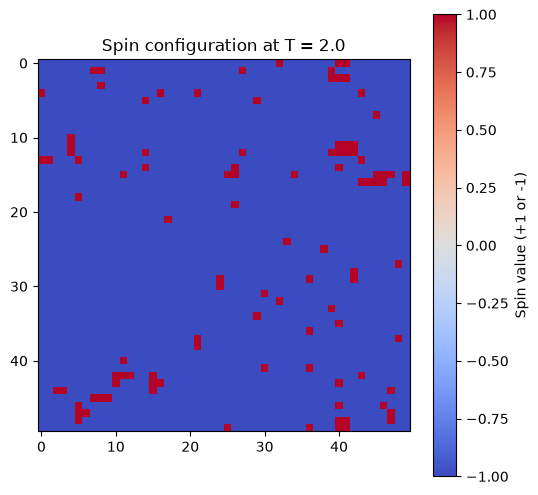

In [8]:
plt.figure(figsize=(6, 6))
plt.imshow(lattice, cmap = 'coolwarm', interpolation='nearest')
plt.title(f"Spin configuration at T = {temperature}")
plt.colorbar(label = "Spin value (+1 or -1)")
plt.show()

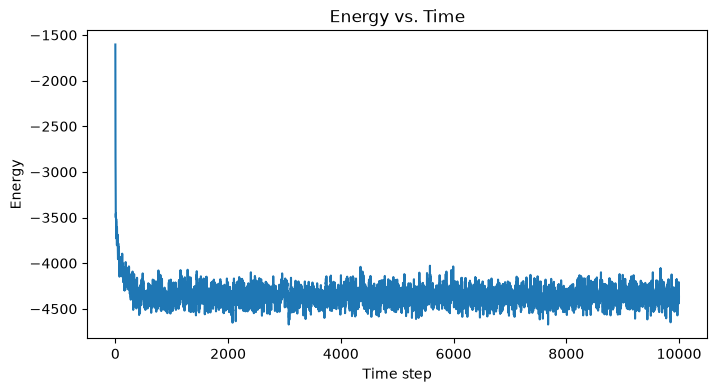

In [9]:
plt.figure(figsize=(8, 4))
plt.plot(energies)
plt.xlabel("Time step")
plt.ylabel("Energy")
plt.title("Energy vs. Time")
plt.show()

# Адаптация под изменение температуры

In [ ]:
@njit
def calculate_energy(lattice, L, J):
    energy = 0
    for i in range(L):
        for j in range(L):
            spin = lattice[i, j]
            neighbors = (lattice[(i+1) % L, j] + lattice[i, (j+1) % L] +
                        lattice[(i-1) % L, j] + lattice[i, (j-1) % L])
            energy += -J * spin * neighbors
    return energy / 2


temperatures = np.linspace(0.5, 4.0, 40)   
L = 30
pressure = 1                                
steps_thermal  = 3000
steps_measure  = 3000

mean_E  = np.zeros(len(temperatures))
mean_E2 = np.zeros(len(temperatures))

for k, T in enumerate(temperatures):
    lattice = np.random.choice([1, -1], size=(L, L))

    # 1) термализация (без измерений!)
    for _ in range(steps_thermal):
        metropolis_step(lattice, T, L, pressure)

    # 2) измерения в равновесии
    Es = np.empty(steps_measure)
    for s in range(steps_measure):
        metropolis_step(lattice, T, L, pressure)
        Es[s] = calculate_energy(lattice, L, pressure)

    mean_E[k]  = Es.mean()
    mean_E2[k] = (Es**2).mean()

# энергия на спин
e_per_spin = mean_E / L**2

# теплоёмкость на спин:  C = (⟨E²⟩ − ⟨E⟩²) / (N T²)
C_per_spin = (mean_E2 - mean_E**2) / (temperatures**2 * L**2)

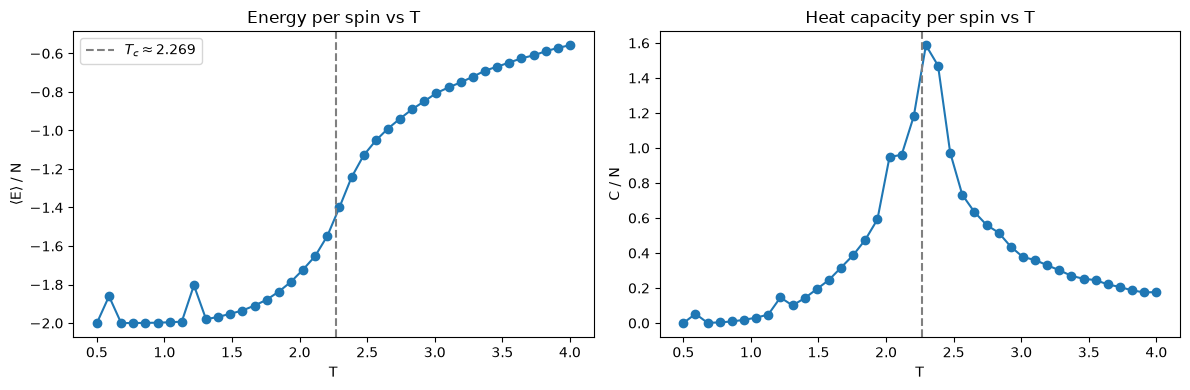

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(temperatures, e_per_spin, 'o-')
ax[0].axvline(2.269, ls='--', color='gray', label=r'$T_c \approx 2.269$')
ax[0].set_xlabel("T")
ax[0].set_ylabel("⟨E⟩ / N")
ax[0].set_title("Energy per spin vs T")
ax[0].legend()

ax[1].plot(temperatures, C_per_spin, 'o-')
ax[1].axvline(2.269, ls='--', color='gray')
ax[1].set_xlabel("T")
ax[1].set_ylabel("C / N")
ax[1].set_title("Heat capacity per spin vs T")

plt.tight_layout()
plt.show()